# Кросс-валидация, подбор гиперпараметров и пайплайны

## Обо мне

🐍 **Эксперт по Python и Data Science**. В 2020 году ушёл из найма, сейчас реализую собственные проекты, занимаюсь IT-образованием и консультированием.

👨‍💻 **Опыт в образовании**. В IT-образовании с 2016 года. За это время провел более 3000 лекций и вебинаров, обучил тысячи студентов, многие из которых сейчас работают в ведущих IT-компаниях. Создаю авторские курсы, консультирую крупные компании по вопросам Data Science и участвую в разработке образовательных программ для университетов и онлайн-школ.

🎯 Стремлюсь сделать обучение качественным и честным для всех, кто хочет развиваться в IT-сфере.

📱 Делюсь полезными материалами в своём [Telegram-канале об IT и AI](https://t.me/oleg_payload).

## Зачем переделывать то, что уже работает

Чуть ранее мы проверяли качество построенной модели, на **тестовым** набором данных. Мы заранее выделяли этот набор данных для того, чтобы рассчитать финальную метрику модели и сделать вывод о том, устраивает ли нас качество моделирования. Такой подход называется **двухкомпонентным**.

 Данные делились на train и test случайно. Стоит поменять `random_state` — цифра изменится, и мы даже не узнаем, насколько сильно. Оценка качества у нас есть, а понимания, насколько ей верить, — нет.


In [ ]:
import pandas as pd
import numpy as n
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     LeaveOneOut, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_score,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.metrics import accuracy_score, recall_score, precision_score

import time
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

## Данные

Берём тот же датасет, что и в занятии про логистическую регрессию: клиенты фитнес-центра, целевая переменная `churn` — ушёл клиент в текущем месяце или нет.

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/obulygin/content/main/gym_churn/gym_churn.csv')
df.columns = df.columns.str.lower()
print(df.shape)
df.head()

(4000, 14)


,gender,near_location,partner,promo_friends,phone,contract_period,group_visits,age,avg_additional_charges_total,month_to_end_contract,lifetime,avg_class_frequency_total,avg_class_frequency_current_month,churn
0,1,1,1,1,0,6,1,29,14.227470,5,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,13,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,2,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,2,3,1.113884,1.120078,0


Признаки и их смысл разбирали ранее, поэтому подготовку повторяем коротко: убираем колонки, которые не несут пользы для модели по результатам корреляционного анализа.

In [ ]:
df = df.drop(['contract_period', 'avg_class_frequency_total', 'phone', 'gender'], axis=1)

X = df.drop('churn', axis=1)
y = df['churn']

print(f'Признаков: {X.shape[1]}')
print(f'Доля оттока: {y.mean():.3f}')

Признаков: 9
Доля оттока: 0.265


In [ ]:
scores = {'accuracy': [], 'recall': []}

for seed in range(20):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, random_state=seed, stratify=y)
    model = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)

    scores['accuracy'].append(accuracy_score(y_te, pred))
    scores['recall'].append(recall_score(y_te, pred))

scores = pd.DataFrame(scores)

for name in scores:
    s = scores[name]
    print(f'{name:9s}: {s.min():.4f} … {s.max():.4f} | среднее {s.mean():.4f} | '
          f'std {s.std():.4f} | размах {s.max() - s.min():.4f}')

accuracy : 0.8970 … 0.9220 | среднее 0.9079 | std 0.0074 | размах 0.0250
recall   : 0.7811 … 0.8415 | среднее 0.8166 | std 0.0179 | размах 0.0604


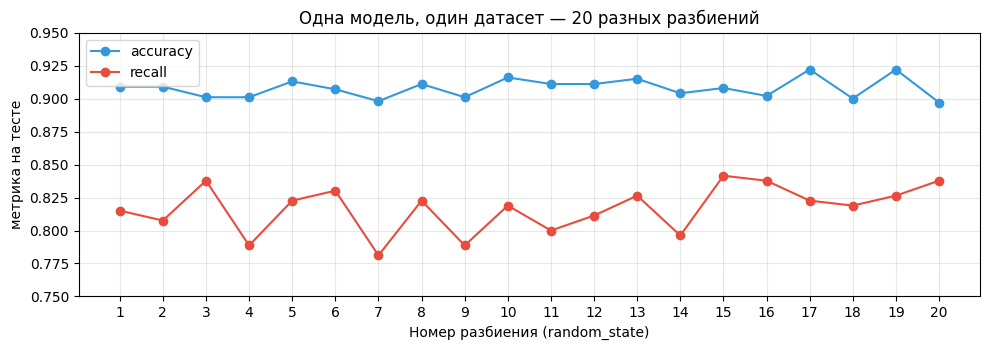

In [ ]:
plt.figure(figsize=(10, 3.6))

for name, color in [('accuracy', '#3498db'), ('recall', '#e74c3c')]:
    plt.plot(range(1, 21), scores[name], marker='o', label=name, color=color)

plt.xticks(range(1, 21))
plt.xlabel('Номер разбиения (random_state)')
plt.ylabel('метрика на тесте')
plt.title('Одна модель, один датасет — 20 разных разбиений')
plt.ylim(0.75, 0.95)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Вывод:** модель одна, данные одни — а результат гуляет. Accuracy меняется на 2.6 процентных пункта (0.897–0.923), recall — на **6.4** (0.781–0.845). Разброс recall в два с половиной раза больше, потому что он считается по меньшему классу: 265 положительных объектов в тесте на 20 разбиениях тасуются заметно.

Обратите внимание: стандартное отклонение у recall 0.0183 против 0.0075 у accuracy.
Вторая проблема — неполное использование данных: при разбиении 75/25 четверть объектов никогда не участвует в обучении.

## Hold-out: три выборки вместо двух

Для подбора гиперпараметров двух выборок мало: подбирая параметры по тесту, мы подгоняем модель под тест. Поэтому в проектах используют три набора:

| Выборка | Для чего |
|---|---|
| **train** (обучающая) | обучение модели, подбор внутренних параметров |
| **validation** (валидационная) | сравнение моделей и подбор гиперпараметров |
| **test** (тестовая) | финальная оценка, **один раз** в самом конце |

Представим, что мы готовим студентов к олимпиаде по программированию. На этом "трейне":
- Студенты решают множество задач.
- Преподаватели дают обратную связь и помогают исправить ошибки.

Далее мы проводим внутренние соревнования чтобы выбрать студента, который отправиться на олимпиаду - это валидация.

На самой олимпиаде (тесте) выбранный студент (наша модель) показывает свои навыки в реальных условиях. Это его окончательная проверка.

Такой подход называют **hold-out**: валидация «отложена» один раз и больше не пересобирается.

In [ ]:
# 60% — обучение, 20% — валидация, 20% — тест
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.4,
                                                    random_state=RANDOM_STATE, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_rest, y_rest, test_size=0.5,
                                                    random_state=RANDOM_STATE, stratify=y_rest)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_valid = scaler.transform(X_valid)
print(f'train: {X_train.shape[0]:4d} ({y_train.mean():.3f} оттока)')
print(f'valid: {X_valid.shape[0]:4d} ({y_valid.mean():.3f} оттока)')
print(f'test:  {X_test.shape[0]:4d} ({y_test.mean():.3f} оттока)')

train: 2400 (0.265 оттока)
valid:  800 (0.265 оттока)
test:   800 (0.265 оттока)


In [ ]:
model_holdout = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
model_holdout.fit(X_train, y_train)

for name, X_part, y_part in [('train', X_train, y_train),
                             ('valid', X_valid, y_valid),
                             ('test ', X_test, y_test)]:
    pred = model_holdout.predict(X_part)
    print(f'{name}: accuracy = {accuracy_score(y_part, pred):.4f}, '
          f'recall = {recall_score(y_part, pred):.4f}')

train: accuracy = 0.9117, recall = 0.8195
valid: accuracy = 0.8938, recall = 0.8066
test : accuracy = 0.9225, recall = 0.8019


**Что видно:**

- на train recall 0.8226, на валидации 0.8066, на тесте 0.7972 — во всех трёх случаях это одна и та же модель, и разница между ними ничем, кроме состава выборки, не объясняется;
- расхождение valid и test — почти процентный пункт по recall. Это и есть цена «одного броска монеты»: одна отложенная выборка не говорит, насколько цифра случайна, она просто даёт другую цифру;
- 20% данных ушли из обучения. Чем меньше датасет, тем дороже эта плата.

**Преимущества**:
- Очень простой и понятный.
- Чаще всего применяется на больших датасетах, так как требует значительно меньше вычислительных мощностей, чем другие методы.
   


**Недостатки**:  
Разбиение производится случайным образом и оценка в этом методе зависит от того, какие наблюдения попали в набор для валидации. Это плохо, так как возможна ситуация, когда распределение целевого признака в тренировочной, валидационной (и тестовой) выборках может значительно различаться, и оценка качества может быть необъективной.


## Кросс-валидация (k-fold)

Метод k-fold более известен как кросс-валидация (cross validation), или перекрёстный контроль.

Это самый популярный метод валидации для оценки качества моделирования, и он используется практически во всех проектах. Эта идея также применяется во многих моделях и методах машинного обучения, например в стекинге.

Алгоритм кросс-валидации:  
- Датасет разбивается на N одинаковых частей . Эти части называются фолдами.
- Далее происходит N итераций, во время каждой из которых один фолд выступает в роли валидационного множества, а объединение остальных — в роли тренировочного. Модель учится на
N-1 фолде и проверяется на оставшемся.

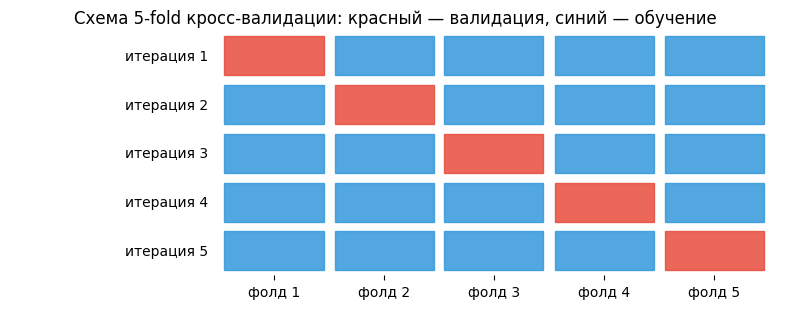

In [ ]:
n_splits = 5

fig, ax = plt.subplots(figsize=(8, 3.2))
for fold in range(n_splits):
    for block in range(n_splits):
        color = '#e74c3c' if block == fold else '#3498db'
        ax.add_patch(plt.Rectangle((block + 0.05, n_splits - fold - 0.9), 0.9, 0.8,
                                   color=color, alpha=0.85))
    ax.text(-0.1, n_splits - fold - 0.5, f'итерация {fold + 1}',
            ha='right', va='center', fontsize=10)

ax.set_xlim(-1.9, n_splits + 0.1)
ax.set_ylim(0, n_splits)
ax.set_yticks([])
ax.set_xticks(np.arange(n_splits) + 0.5)
ax.set_xticklabels([f'фолд {i + 1}' for i in range(n_splits)])
ax.set_title('Схема 5-fold кросс-валидации: красный — валидация, синий — обучение')
for spine in ax.spines.values():
    spine.set_visible(False)
plt.tight_layout()
plt.show()

Благодаря такому подходу мы избавляемся от необходимости создавать отложенную валидационную выборку — мы генерируем её искусственно на каждом из этапов кросс-валидации из исходного набора данных. Каждая из  частей исходного обучающего набора данных используется в качестве валидационной выборки.

Для больших наборов данных в качестве значения  часто берут 10, то есть выборка разбивается на десять фолдов. В случае маленьких выборок  берут равным 3 или 5.

 Чем больше `k`, тем больше моделей будут обучаться, тем объективнее будет оценка качества, однако тем больше времени займёт процесс валидации.

**Преимущества**:  
Подход позволяет получить более устойчивую к выбросам оценку качества модели, так как модель обучается на нескольких независимых наборах данных.
Значения метрик получаются более объективными.

**Недостатки**:  
Подход предусматривает, что мы обучаем одну и ту же модель несколько раз, что, очевидно, плохо сказывается на производительности. Если модель обучается довольно медленно, то валидация может занять очень много времени.

В библиотеке sklearn метод k-fold реализован в классе [KFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html). А для дальнейшей оценки модели на кросс-валидации удобно использовать функцию [cross_validate](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html).

Основные параметры функции `cross_validate()`:

- **estimator** — модель, качество которой будет проверяться на кросс-валидации.
- **X** — матрица наблюдений.
- **y** — вектор-столбец правильных ответов.
- **cv** — кросс-валидатор из библиотеки sklearn (например, KFold) или количество фолдов, на которые необходимо разбить выборку. По умолчанию используется кросс-валидация на пяти фолдах.
- **scoring** — название метрики в виде строки либо функция для её вычисления ('accuracy', 'precision', 'recall', 'f1' и другие; полный список — в документации к функции).
- **return_train_score** — параметр, указывающий стоит ли возвращать значения метрики, полученные на тренировочных фолдах. По умолчанию — False, то есть метрики считаются только на валидационных фолдах.

Функция возвращает словарь со следующими ключами:
- **fit_time** — время обучения модели на каждой итерации кросс-валидации;
- **score_time** — время вычисления метрик на каждой итерации кросс-валидации;
- **test_score** — значения метрик на валидационных фолдах;
- **train_score** — значения метрик на тренировочных фолдах.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
lr_model = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_metrics = cross_validate(
    estimator=lr_model,
    X=X_train,
    y=y_train,
    cv=kf,
    scoring=['accuracy', 'recall'],
    return_train_score=True,
    n_jobs=-1
)


In [ ]:
pd.DataFrame(cv_metrics).round(4)

,fit_time,score_time,test_accuracy,train_accuracy,test_recall,train_recall
0,0.0220,0.0153,0.9133,0.9133,0.8302,0.8273
1,0.0203,0.0087,0.9033,0.9154,0.8141,0.8281
2,0.0102,0.0091,0.9033,0.9142,0.8045,0.8185
3,0.0208,0.0155,0.9200,0.9117,0.8397,0.8328
4,0.0101,0.0067,0.9200,0.9133,0.8425,0.8354


In [ ]:
print('recall по фолдам:', np.round(cv_metrics['test_recall'], 4))

summary = pd.DataFrame({
    'метрика': ['accuracy', 'recall'],
    'на train (среднее)': [cv_metrics['train_accuracy'].mean(), cv_metrics['train_recall'].mean()],
    'на валидации (среднее)': [cv_metrics['test_accuracy'].mean(), cv_metrics['test_recall'].mean()],
    'на валидации (std)': [cv_metrics['test_accuracy'].std(), cv_metrics['test_recall'].std()],
})

summary.round(4)

recall по фолдам: [0.8302 0.8141 0.8045 0.8397 0.8425]


,метрика,на train (среднее),на валидации (среднее),на валидации (std)
0,accuracy,0.9136,0.9120,0.0075
1,recall,0.8284,0.8262,0.0147


**Что смотреть в таблице:**

- **Среднее на валидации** — честная оценка качества. Именно её пишут в отчёт и сравнивают между моделями.
- **std** — устойчивость.
- **Разрыв train и валидации** — первый признак переобучения. З


### Сколько фолдов брать

| k | Когда использовать |
|---|---|
| 3 | очень мало данных или очень дорогое обучение |
| **5** | рабочий вариант по умолчанию |
| 10 | данных достаточно, нужна точная оценка |


Чем больше `k`, тем больше обучений и тем дольше счёт. И есть вторая сторона: чем мельче фолды, тем шумнее метрика на каждом из них. На 4000 строк это ещё незаметно, на 200 — уже критично.

Метод k-Fold даёт более надёжную оценку качества модели, чем hold-out, так как обучение и тест модели происходят на разных подмножествах исходного датасета. Однако проведение
 итераций обучения и теста может быть вычислительно затратным, и поэтому метод обычно применяют либо когда данных достаточно мало, либо при наличии большого количества вычислительных ресурсов, позволяющих проводить все
 итераций параллельно.

### StratifiedKFold

Есть нюанс. При обычном `KFold` фолды нарезаются без учёта целевой переменной. Если данных мало или класс несбалансирован, доли классов в фолдах разъедутся, и оценка станет нестабильной.

`StratifiedKFold` сохраняет долю классов в каждом фолде.

Проверим на наших данных.

In [ ]:
shares_kfold, shares_strat = [], []

for _, val_idx in KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train):
    shares_kfold.append(y_train.iloc[val_idx].mean())

for _, val_idx in StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train):
    shares_strat.append(y_train.iloc[val_idx].mean())

print('Доля оттока в валидационных фолдах')
print(f'  KFold:            {np.round(shares_kfold, 3)}  разброс {np.std(shares_kfold):.4f}')
print(f'  StratifiedKFold:  {np.round(shares_strat, 3)}  разброс {np.std(shares_strat):.4f}')

Доля оттока в валидационных фолдах
  KFold:            [0.27  0.283 0.282 0.237 0.275]  разброс 0.0170
  StratifiedKFold:  [0.268 0.268 0.27  0.27  0.27 ]  разброс 0.0008


**Вывод:** стратификация выравнивает фолды. На четырёх тысячах объектов разница в разбросе небольшая, но на выборке в сотню строк и на редком классе (5% и меньше) `KFold` может дать фолд, где положительного класса нет вообще, — и метрика развалится.



In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)

cv_res = cross_validate(model, X_train, y_train, cv=skf,
                        scoring=['accuracy', 'recall'],
                        return_train_score=True, n_jobs=-1)

pd.DataFrame(cv_res).round(4)

,fit_time,score_time,test_accuracy,train_accuracy,test_recall,train_recall
0,0.0114,0.0101,0.9117,0.9100,0.8447,0.8269
1,0.0120,0.0091,0.9017,0.9112,0.8323,0.8176
2,0.0133,0.0084,0.9017,0.9108,0.7407,0.8297
3,0.0118,0.0070,0.9050,0.9096,0.8210,0.8235
4,0.0125,0.0103,0.9233,0.9067,0.8827,0.8189


In [ ]:
print('recall по фолдам:', np.round(cv_res['test_recall'], 4))

summary = pd.DataFrame({
    'метрика': ['accuracy', 'recall'],
    'на train (среднее)': [cv_res['train_accuracy'].mean(), cv_res['train_recall'].mean()],
    'на валидации (среднее)': [cv_res['test_accuracy'].mean(), cv_res['test_recall'].mean()],
    'на валидации (std)': [cv_res['test_accuracy'].std(), cv_res['test_recall'].std()],
})

summary.round(4)

recall по фолдам: [0.8447 0.8323 0.7407 0.821  0.8827]


,метрика,на train (среднее),на валидации (среднее),на валидации (std)
0,accuracy,0.9097,0.9087,0.0082
1,recall,0.8233,0.8243,0.0467


### Leave-one-out

Крайний случай: `k` равно числу объектов. Модель обучается `n` раз, каждый раз оставляя один объект на проверку.

**Плюсы:** данные используются максимально полно; на крошечных выборках это единственный способ хоть что-то оценить.

**Минусы:** `n` обучений вместо `k` — на 4000 объектов это 4000 обучений; оценка смещена вверх, потому что модель каждый раз учится почти на всём объёме.

Важная деталь: на одном объекте **recall не посчитать** — в фолде из одной строки нет положительных объектов, а значит, $TP + FN = 0$ и метрика не определена. Поэтому для leave-one-out берут accuracy: она считается по одному предсказанию.


In [ ]:
from sklearn.model_selection import LeaveOneOut

lou = LeaveOneOut()

cv_metrics = cross_validate(
    estimator=lr_model,
    X=X_train,
    y=y_train,
    cv=lou,
    scoring='accuracy',  #
    return_train_score=True,
    n_jobs=-1
)



In [ ]:
pd.DataFrame(cv_metrics).round(4)

,fit_time,score_time,test_score,train_score
0,0.0338,0.0159,1.0,0.9096
1,0.0137,0.0028,1.0,0.9093
2,0.0133,0.0047,1.0,0.9096
3,0.0139,0.0027,1.0,0.9096
4,0.0160,0.0024,1.0,0.9093
...,...,...,...,...
2995,0.0117,0.0024,1.0,0.9096
2996,0.0111,0.0026,0.0,0.9100
2997,0.0163,0.0023,1.0,0.9096
2998,0.0130,0.0021,1.0,0.9096


In [ ]:

summary = pd.DataFrame({
    'метрика': ['accuracy'],
    'на train (среднее)': [cv_metrics['train_score'].mean()],
    'на валидации (среднее)': [cv_metrics['test_score'].mean()],
    'на валидации (std)': [cv_metrics['test_score'].std()],
})

summary.round(4)

,метрика,на train (среднее),на валидации (среднее),на валидации (std)
0,accuracy,0.9096,0.908,0.289




Времени ушло в шесть десятков раз больше. Отсюда правило: LOO — инструмент для выборок в сотню объектов, где каждый на счету.

### Repeated k-Fold cross-validation

Является расширение метода KFold, при котором процедура KFold повторяется несколько раз с различными случайными разбиениями данных на фолды. Это позволяет уменьшить вариативность оценки модели и получить более стабильные результаты.

Как он работает?

- Многократное разбиение данных: Данные многократно разбиваются на k подвыборок.
- Повторение KFold: В каждом повторении процедура KFold выполняется как обычно: данные делятся на k фолдов, и модель обучается и тестируется k раз.
- Оценка модели: Средние значения метрик по всем фолдам во всех повторениях используются для более точной оценки модели.

In [ ]:
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

start = time.time()
rep_res = cross_validate(lr_model, X_train, y_train, cv=rskf,
                         scoring='recall', return_train_score=True, n_jobs=-1)
time_rep = time.time() - start

# для сравнения — обычный 5-fold на тех же данных
base_cv = cross_validate(lr_model, X_train, y_train, cv=skf, scoring='recall', n_jobs=-1)

for name, res, t in [('5-fold', base_cv, 0), ('Repeated 5x5', rep_res, time_rep)]:
    scores = res['test_score']
    se = scores.std() / np.sqrt(len(scores))
    print(f'{name:14s} recall = {scores.mean():.4f} ± {scores.std():.4f} | '
          f'ошибка среднего {se:.4f} | значений {len(scores)} | время {t:.2f} с')

5-fold         recall = 0.8243 ± 0.0467 | ошибка среднего 0.0209 | значений 5 | время 0.00 с
Repeated 5x5   recall = 0.8213 ± 0.0405 | ошибка среднего 0.0081 | значений 25 | время 0.20 с


Тут мы создаем объект RepeatedKFold с `n_splits=5`, что означает, что мы хотим разделить данные на 5 фолдов. Мы также указываем `n_repeats=5`, что означает, что мы хотим повторить процесс кросс-валидации пять раз на разных случайных разбиениях.

Но и у этого подхода есть и недостатки. Обычный k-Fold  гарантирует, что модель будет протестирована на всех объектах выборки, в то время как Repeated k-Fold основан на рандомизации, что означает, что некоторые образцы могут вообще не попасть в проверочные наборы. А некоторые объекты могут попасть туда несколько раз.

Repeated не улучшает модель, он уточняет оценку.

Repeated берут, когда сравнивают модели, отличающиеся на сотые доли метрики: он сужает интервал, в котором лежит среднее.

**У этого подхода есть аналогичный вариант со стратификацией.**

## Пайплайны

До этого момента мы аккуратно делили данные и обучали модель. Но есть шаг, который легко портит всю кросс-валидацию, — преобразования данных.

Правило, из которого всё вытекает: **все подсчёты, которые делаются по данным, должны происходить только на обучающей части** — и заново на каждом фолде. Масштабирование, заполнение пропусков, кодирование категорий, отбор признаков, балансировка классов — всё это что-то считает: среднее, медиану, частоту, важность.

Когда `cross_validate` режет `X_train` на фолды, она ничего не знает про эти преобразования. Если мы сделали их **до** кросс-валидации, параметры посчитаны на всех фолдах сразу — включая тот, который потом станет валидацией. Валидация «знает» про обучающие данные. Это и есть **утечка данных (data leakage)**: оценка растёт, а модель лучше не становится.


В sklearn для решения этой проблемы есть класс `Pipeline` и функция `make_pipeline`: в нём можно перечислить шаги работы с данными вплоть до применения модели.



### Pipeline и make_pipeline

Пайплайн — это конвейер: список шагов, которые применяются по порядку; последний шаг — модель.

Есть 2 варианта их создания:

```python
# имена шагов придумываются по имени класса: standardscaler, logisticregression
pipe = make_pipeline(StandardScaler(), LogisticRegression())

# имена свои — нужны, когда параметры перебираются через GridSearchCV
pipe = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression())])
```

In [ ]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])

print(pipe)
print()
print('Шаги пайплайна:', [name for name, _ in pipe.steps])

# то же самое короче: make_pipeline сам называет шаги по имени класса
pipe_short = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
)
print()
print('make_pipeline:', [name for name, _ in pipe_short.steps])

Pipeline(steps=[('scaler', StandardScaler()),
                ('poly', PolynomialFeatures(include_bias=False)),
                ('model', LogisticRegression(max_iter=5000, random_state=42))])

Шаги пайплайна: ['scaler', 'poly', 'model']

make_pipeline: ['standardscaler', 'polynomialfeatures', 'logisticregression']


При использовании пайпланой в каждой итерации кросс-валидации все будет вычисляться только на текущих тренировочных фолдах, а применятся к текущим валидационным фолдам.

Это гарантирует, что тренировочные данные не будут "подглядывать" информацию из валидационных данных за пределами текущего фолда, что обеспечивает честную оценку модели.

In [ ]:
pipe.fit(X_train, y_train)



Pipeline(steps=[('scaler', StandardScaler()),
                ('poly', PolynomialFeatures(include_bias=False)),
                ('model', LogisticRegression(max_iter=5000, random_state=42))])

In [ ]:
# все шаги, кроме последнего (модели)
X_train_transformed = pipe[:-1].transform(X_train)
print(f'Признаков было: {X_train.shape[1]}, после преобразований: {X_train_transformed.shape[1]}')
print(f'recall на валидации: {recall_score(y_valid, pipe.predict(X_valid)):.4f}')

Признаков было: 9, после преобразований: 54
recall на валидации: 0.7972


In [ ]:
y_test_pred = pipe.predict(X_test)

print(f"Среднее качество на тренировочной выборке: {cv_metrics['train_score'].mean()}")
print(f"Среднее качество на валидационной выборке: {cv_metrics['test_score'].mean()}")

print(f'Качество на тесте: {recall_score(y_test, y_test_pred):.4f}')

Среднее качество на тренировочной выборке: 0.9095893075469601
Среднее качество на валидационной выборке: 0.908
Качество на тесте: 0.7945


Обратите внимание: `pipe.fit` обучает преобразования **на train**, а `predict` применяет их к новым данным без переобучения.

## Техники подбора гиперпараметров

Для начала вспомним, в чём отличие параметров модели от гиперпараметров: параметры настраиваются в процессе обучения модели на данных. Например, веса в линейной регрессии, нейросетях, структура решающего дерева;
гиперпараметры — это характеристики модели, которые фиксируются до начала обучения: глубина решающего дерева, значение силы регуляризации в линейной модели, learning rate для градиентного спуска.

Качество модели может очень сильно варьироваться в зависимости от гиперпараметров, поэтому существуют разнообразные методы и инструменты для их подбора. Если нас есть несколько моделей разной природы, то нужно для каждой из моделей подобрать гиперпараметры, а затем модели с наилучшими гиперпараметрами сравнить между собой.

В прошлый раз мы с вами поступали достаточно примитивно - подбирали коэффиценты регуляризации для моделей в цикле. Теперь пора узнать, какие более удобные инструменты для этого можно использовать.

## GridSearchCV


Наиболее часто используемый метод — это поиск по сетке (grid search), который по сути является попыткой перебрать все возможные комбинации заданных гиперпараметров. Мы указываем список значений для различных гиперпараметров, и, ориентируясь на нашу метрику, оцениваем эффективность модели для каждого их сочетания, чтобы получить оптимальную комбинацию значений.

По факту модель будет обучена столько раз, сколько комбинаций есть, столько же раз будет рассчитана метрика.

При этом для лучшей оценки обобщающей способности кросс-валидация уже встроена в этом класс.


Основные параметры:

- **estimator** — модель, которую будем оптимизировать;
- **param_grid** — словарь с именами гиперпараметров (в формате строки (str), например, 'max_depth') в качестве ключей и последовательностями параметров (например, [5, 8, 10]) в качестве значений.
- **scoring** — по умолчанию используется score-функция заданного алгоритм. Можно задать любую метрику.
- **cv** — количество фолдов в кросс-валидации, по умолчанию используется 5.
- **n_jobs** — количество ядер для распараллеливания расчёта. -1 использует все существующие ядра.

Если модель внутри пайплайна, имя параметра пишется через двойное подчёркивание: `model__C`, `model__l1_ratio`. Это не синтаксис Python, а адрес шага внутри пайплайна: «шаг `model`, параметр `C`».

Pipeline и GridSearchCV работают вместе, чтобы автоматически выполнять преобразования и подбор гиперпараметров для вашей модели. Когда вы используете GridSearchCV с Pipeline, все преобразования, определенные в Pipeline, выполняются на каждой итерации перекрестной проверки независимо.

Это означает, что для каждой итерации перекрестной проверки данные разбиваются на обучающую и валидационную выборки. Затем все преобразования, определенные в Pipeline, применяются к обучающей выборке независимо. После этого модель обучается на преобразованных обучающих данных и оценивается на преобразованных валидационных данных. Этот процесс повторяется для каждой итерации перекрестной проверки.

Таким образом, все преобразования выполняются независимо на каждой итерации перекрестной проверки, а не на всей обучающей выборке целиком. Это позволяет избежать утечки данных между обучающей и валидационной выборками и обеспечивает более точную оценку качества модели.

Сетку параметров при использвоании `pipeline` нужно задавать в особом формате, где перед названием параметра нужно указывать шаг пайплайна.

In [ ]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(penalty='elasticnet', solver='saga',
                                 max_iter=5000, random_state=RANDOM_STATE)),
])

param_grid = {
    'model__class_weight': [None, 'balanced'],
    'model__C': [0.03, 0.1, 0.3, 1, 3, 10],
    'model__l1_ratio': [0, 0.5, 1],
}



In [ ]:
grid = GridSearchCV(estimator=pipe,
                    param_grid=param_grid,
                    scoring='recall',
                    cv=skf,
                    n_jobs=-1,
                    return_train_score=True)

start = time.time()
grid.fit(X_train, y_train)
time_grid = time.time() - start

print(f'Комбинаций: {len(grid.cv_results_["params"])}, обучений: {len(grid.cv_results_["params"]) * 5}')
print(f'Время: {time_grid:.2f} с')

print(f'recall на кросс-валидации: {grid.best_score_:.4f}')

Комбинаций: 36, обучений: 180
Время: 8.23 с
recall на кросс-валидации: 0.9295


Поиск по сетке не гарантирует, что мы найдём наилучшую комбинацию гиперпараметров. Всё потому, что сетка значений конечна, и фактическое наилучшее значение может отсутствовать или оказаться между значений, заданными нами.

Наилучшая найденная комбинация гиперпараметров сохраняется в атрибуте `best_params_`:

In [ ]:
print(f'Лучшая комбинация: {grid.best_params_}')

Лучшая комбинация: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__l1_ratio': 0.5}


GridSearchCV включает в себя не только поиск лучших параметров, но и автоматическое построение новой модели на всём обучающем наборе данных с использованием параметров, которые дают наилучшее значение метрики при кросс-валидации.



Итоговая модель хранится в параметре `best_estimator_`, ей можно воспользоваться для получения прогнозов на новых данных:



In [ ]:
print(f"Наилучшая модель:\n{grid.best_estimator_}")

Наилучшая модель:
Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(C=0.1, class_weight='balanced',
                                    l1_ratio=0.5, max_iter=5000,
                                    penalty='elasticnet', random_state=42,
                                    solver='saga'))])


In [ ]:
grid.best_estimator_.predict(X_test)

array([0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1,
       0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1,



`cv_results_` — полный протокол поиска: все комбинации, метрики на train и валидации, время, ранг. Смотреть его удобнее таблицей.

In [ ]:
grid_table = pd.DataFrame({
    'class_weight': [str(p['model__class_weight']) for p in grid.cv_results_['params']],
    'C': [p['model__C'] for p in grid.cv_results_['params']],
    'l1_ratio': [p['model__l1_ratio'] for p in grid.cv_results_['params']],
    'recall (CV)': grid.cv_results_['mean_test_score'],
    'std': grid.cv_results_['std_test_score'],
    'recall (train)': grid.cv_results_['mean_train_score'],
}).sort_values('recall (CV)', ascending=False)

grid_table.head(8).round(4)

,class_weight,C,l1_ratio,recall (CV),std,recall (train)
15,balanced,0.30,0.0,0.9295,0.0200,0.9301
10,balanced,0.10,0.5,0.9295,0.0200,0.9301
9,balanced,0.10,0.0,0.9295,0.0149,0.9319
3,balanced,0.03,0.0,0.9282,0.0063,0.9329
16,balanced,0.30,0.5,0.9270,0.0218,0.9295
4,balanced,0.03,0.5,0.9270,0.0152,0.9304
34,balanced,10.00,0.5,0.9245,0.0238,0.9295
29,balanced,3.00,1.0,0.9245,0.0238,0.9295


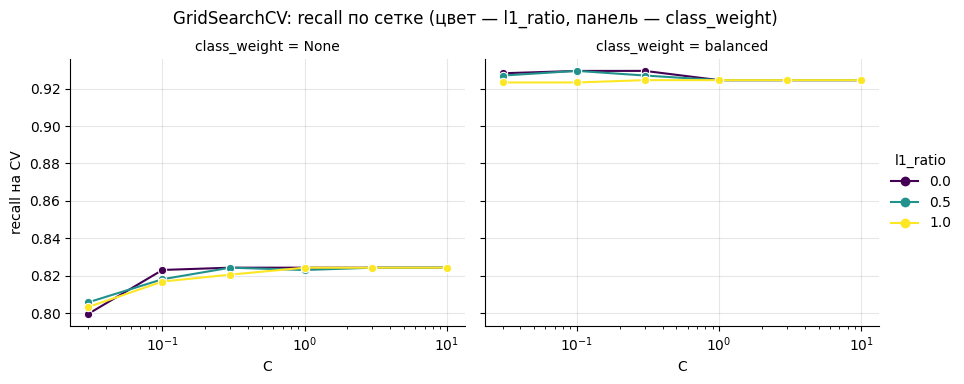

In [ ]:
grid_plot = pd.DataFrame({
    'C': [p['model__C'] for p in grid.cv_results_['params']],
    'l1_ratio': [p['model__l1_ratio'] for p in grid.cv_results_['params']],
    'class_weight': [str(p['model__class_weight']) for p in grid.cv_results_['params']],
    'recall': grid.cv_results_['mean_test_score'],
})

g = sns.relplot(data=grid_plot, x='C', y='recall', hue='l1_ratio', col='class_weight',
                kind='line', marker='o', height=3.6, aspect=1.25, palette='viridis')
g.set(xscale='log')
for ax in g.axes.flat:
    ax.grid(alpha=0.3)
    ax.set_ylabel('recall на CV')
g.fig.suptitle('GridSearchCV: recall по сетке (цвет — l1_ratio, панель — class_weight)', y=1.04)
plt.show()

### Случайный поиск (RandomizedSearchCV)

Как мы видели, `GridSearchCV` может быть очень медленным. **Случайный поиск (Random Search)** предлагает более эффективную альтернативу.

**В чём его суть?**
1.  Мы определяем **пространство поиска** для каждого гиперпараметра:
    *   Это могут быть списки значений (как в Grid Search).
    *   Или, что более гибко, **статистические распределения** (например, равномерное, логнормальное).
2.  Задаём **количество итераций (`n_iter`)** — сколько случайных комбинаций гиперпараметров нужно проверить.
3.  `RandomizedSearchCV` случайным образом выбирает `n_iter` комбинаций из заданного пространства.
4.  Для каждой выбранной комбинации он, как и Grid Search, оценивает качество на кросс-валидации.
5.  Выбирает лучшую из **проверенных** `n_iter` комбинаций.

**Почему это часто работает лучше Grid Search?**

Исследование *Bergstra & Bengio (2012)* показало, что для большинства задач не все гиперпараметры одинаково важны. `GridSearchCV` тратит много ресурсов на точную настройку неважных параметров. `RandomizedSearchCV`, пробуя случайные комбинации, с большей вероятностью найдет хорошие значения для **важных** параметров за то же (или меньшее) количество итераций.


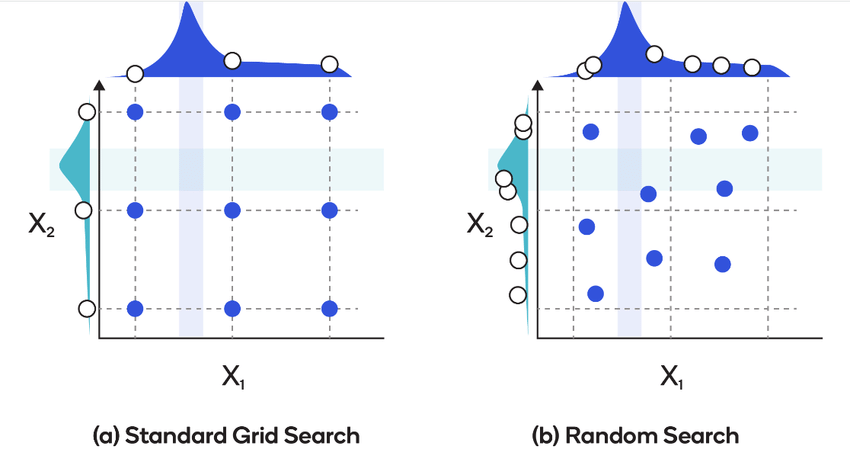

**Логарифмическая шкала**

Для некоторых гиперпараметров, таких как сила регуляризации (`C` в LogisticRegression) или скорость обучения (`learning_rate` в градиентных методах), оптимальные значения часто различаются на *порядки* (например, 0.001, 0.01, 0.1, 1, 10). Искать их в линейной шкале (как `randint(1, 1000)`) неэффективно. Лучше использовать логарифмическую шкалу. Это даст больше шансов попробовать значения типа 0.005, 0.05, 0.5, 5, 50, 500 чем равномерное распределение `uniform(0.001, 1000)`.

Для целочисленных параметров, меняющихся на порядки, можно генерировать степени (например, 2^-5, 2^-4, ..., 2^5).

In [ ]:
from scipy.stats import loguniform
from scipy.stats import uniform


param_dist = {
    'model__class_weight': [None, 'balanced'],
    'model__C': loguniform(1e-2, 1e1),
    'model__l1_ratio': uniform(0, 1),
}

rand = RandomizedSearchCV(estimator=pipe,
                          param_distributions=param_dist,
                          n_iter=20,
                          scoring='recall',
                          cv=skf,
                          n_jobs=-1,
                          random_state=RANDOM_STATE,
                          return_train_score=True)

start = time.time()
rand.fit(X_train, y_train)
time_rand = time.time() - start

print(f'Проверено комбинаций: {len(rand.cv_results_["params"])}')
print(f'Время: {time_rand:.2f} с')
print(f'Лучшая комбинация: {rand.best_params_}')
print(f'recall на кросс-валидации: {rand.best_score_:.4f}')

Проверено комбинаций: 20
Время: 0.53 с
Лучшая комбинация: {'model__C': np.float64(0.0420557118700721), 'model__class_weight': 'balanced', 'model__l1_ratio': np.float64(0.18485445552552704)}
recall на кросс-валидации: 0.9295


**Плюсы и минусы `RandomizedSearchCV`**

**Плюсы:**
*   **Эффективность:** Значительно быстрее `GridSearchCV` при большом количестве гиперпараметров или широких диапазонах. Часто находит сравнимое или даже лучшее решение за меньшее время.
*   **Гибкость:** Позволяет использовать распределения для задания пространства поиска, что лучше подходит для непрерывных или логарифмических параметров.
*   **Контроль времени:** Вы сами задаете бюджет (`n_iter`), сколько комбинаций проверить.

**Минусы:**
*   **Случайность:** Результат зависит от `random_state`. Нет гарантии, что будет найдено абсолютное оптимальное решение (даже в рамках заданных диапазонов).
*   **Меньшая систематичность:** Может пропустить какие-то интересные области, если `n_iter` недостаточно велико.

## HalvingSearchCV

In [ ]:
# Важно! Halving Search все еще экспериментальная фича в scikit-learn (на момент написания),
# поэтому ее нужно явно импортировать таким образом:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV, HalvingRandomSearchCV

Мы видели, что `GridSearchCV` может быть очень медленным из-за полного перебора, а `RandomizedSearchCV` эффективнее, но все равно оценивает каждую из `n_iter` комбинаций на *полном* объеме данных (через CV).

**Проблема:** Значительная часть времени тратится на оценку "плохих" комбинаций гиперпараметров. Если бы мы могли быстро идентифицировать и отбросить их, не тратя полный цикл CV, мы бы сэкономили много времени.

**Идея:** А что если оценивать *все* (или много) комбинаций на *небольшой* части данных, отбрасывать худшие, а оставшимся давать *больше* данных для более точной оценки?

Это и есть основной принцип методов, основанных на **Successive Halving**.

`scikit-learn` предоставляет два таких инструмента:
*   `HalvingGridSearchCV`: Применяет идею Successive Halving к сетке параметров (`param_grid`).
*   `HalvingRandomSearchCV`: Применяет идею Successive Halving к случайному выбору параметров (`param_distributions`).

**Концепция Successive Halving:**

1.  **Итерация 1:**
    *   Берутся **все** кандидаты (комбинации ГП из сетки или случайно выбранные).
    *   Каждый кандидат оценивается на **небольшом** количестве ресурсов (например, на малой доле обучающих данных `n_samples`).
2.  **Итерация 2:**
    *   Выбирается **доля лучших** кандидатов (определяется параметром `factor`). Худшие отбрасываются.
    *   Оставшимся кандидатам выделяется **больше ресурсов** (например, в `factor` раз больше `n_samples`). Они переобучаются и оцениваются на этих увеличенных ресурсах.
3.  **Последующие итерации:**
    *   Процесс повторяется: выбирается доля лучших из оставшихся, им дается еще больше ресурсов, они переобучаются и оцениваются.
4.  **Финал:** Процесс продолжается, пока не останется небольшое число лучших кандидатов, оцененных на максимально доступном количестве ресурсов (в идеале, на всех обучающих данных).

**Параметры:**

*   `factor` (float, >=2): Коэффициент уменьшения числа кандидатов и увеличения ресурсов на каждой итерации. Например, `factor=3` означает, что на следующий раунд проходит 1/3 лучших кандидатов, и им дается в 3 раза больше ресурсов.
*   `resource` (str): Ресурс, который увеличивается с итерациями. По умолчанию и чаще всего используется `'n_samples'` - количество обучающих объектов.
*   `min_resources` (int или 'exhaust'): Минимальное количество ресурсов, выделяемое кандидатам на первой итерации.
    *   Если `int`: Задает конкретное число (например, `min_resources=100` - начать со 100 объектов).
    *   Если `'exhaust'`: `scikit-learn` автоматически вычисляет `min_resources` так, чтобы на последней итерации использовались почти все доступные ресурсы (максимально возможный `n_samples` для CV). Это часто удобный вариант.
*   `aggressive_elimination` (bool): Если `True`, позволяет отбросить больше кандидатов на первой итерации, если их много. Может ускорить процесс, но есть риск отбросить что-то хорошее. По умолчанию `False`.

Попробуем `HalvingGridSearchCV` с той же сеткой, что и для `GridSearchCV`, и `HalvingRandomSearchCV` с тем же пространством и числом итераций, что и для `RandomizedSearchCV`.

In [ ]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV

halving = HalvingGridSearchCV(estimator=pipe,
                              param_grid=param_grid,
                              scoring='recall',
                              cv=skf,
                              factor=2,
                              n_jobs=-1,
                              random_state=RANDOM_STATE)

start = time.time()
halving.fit(X_train, y_train)
time_halving = time.time() - start

print(f'Время: {time_halving:.2f} с')
print(f'Лучшая комбинация: {halving.best_params_}')
print(f'recall на кросс-валидации: {halving.best_score_:.4f}')

Время: 1.47 с
Лучшая комбинация: {'model__C': 0.03, 'model__class_weight': 'balanced', 'model__l1_ratio': 0}
recall на кросс-валидации: 0.9302


In [ ]:
halving_random_search = HalvingRandomSearchCV(
    estimator=pipe,
    param_distributions=param_dist,
    n_candidates='exhaust',
    factor=2,
    resource='n_samples',
    min_resources=20,          # Укажем минимум 20 сэмплов для старта (можно 'exhaust')
    scoring='recall',
    cv=skf,
    n_jobs=-1,
    verbose=1,
    random_state=42
)



In [ ]:
print("\nЗапуск HalvingRandomSearchCV...")
start_time_hrandom = time.time()
halving_random_search.fit(X_train, y_train)
end_time_hrandom = time.time()
hrandom_time = end_time_hrandom - start_time_hrandom
print(f"HalvingRandomSearchCV завершен за {hrandom_time:.2f} секунд.")




Запуск HalvingRandomSearchCV...
n_iterations: 8
n_required_iterations: 8
n_possible_iterations: 8
min_resources_: 20
max_resources_: 3000
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 150
n_resources: 20
Fitting 5 folds for each of 150 candidates, totalling 750 fits
----------
iter: 1
n_candidates: 75
n_resources: 40
Fitting 5 folds for each of 75 candidates, totalling 375 fits
----------
iter: 2
n_candidates: 38
n_resources: 80
Fitting 5 folds for each of 38 candidates, totalling 190 fits
----------
iter: 3
n_candidates: 19
n_resources: 160
Fitting 5 folds for each of 19 candidates, totalling 95 fits
----------
iter: 4
n_candidates: 10
n_resources: 320
Fitting 5 folds for each of 10 candidates, totalling 50 fits
----------
iter: 5
n_candidates: 5
n_resources: 640
Fitting 5 folds for each of 5 candidates, totalling 25 fits
----------
iter: 6
n_candidates: 3
n_resources: 1280
Fitting 5 folds for each of 3 candidates, totalling 15 fits
----------
iter: 7
n_can

#### Визуализация процесса HalvingSearch

Чтобы лучше понять, как `HalvingSearch` отсеивает кандидатов и увеличивает ресурсы, можно проанализировать и визуализировать данные из его атрибута `cv_results_`. В нем содержатся дополнительные столбцы, такие как `iter` (номер итерации) и `n_resources` (количество ресурсов, использованных на данной итерации).

Давайте посмотрим на результаты `HalvingRandomSearchCV`, так как он обычно интереснее из-за случайного выбора кандидатов.


In [ ]:


res = pd.DataFrame(halving.cv_results_)

# 1. params разворачивать руками не надо: Halving* уже отдаёт param_<имя> колонки
param_cols = [c for c in res.columns if c.startswith('param_')]
print(param_cols)
# ['param_model__C', 'param_model__class_weight', 'param_model__l1_ratio']

# 2. Весь протокол: iter по возрастанию (от дешёвых итераций к дорогим),
#    внутри итерации — по recall по убыванию
res[['iter', 'n_resources'] + param_cols + ['mean_test_score', 'std_test_score']] \
    .sort_values(['iter', 'mean_test_score'], ascending=[True, False]) \
    .round(4)

# 3. Честный рейтинг — только последняя итерация: mean_test_score
#    на разных n_resources несравним (на iter=0 recall считается по 20 объектам)
last_iter = res['iter'].max()
res.loc[res['iter'] == last_iter, param_cols + ['mean_test_score', 'std_test_score']] \
    .sort_values('mean_test_score', ascending=False) \
    .head(5).round(4)

# 4. Итог: best_score_ уже посчитан на полном ресурсе — его и сравниваем с Grid/Random
print(halving.best_params_)
print(f"recall (CV) = {halving.best_score_:.4f} на {res['n_resources'].max()} объектах")


['param_model__C', 'param_model__class_weight', 'param_model__l1_ratio']
{'model__C': 0.03, 'model__class_weight': 'balanced', 'model__l1_ratio': 0}
recall (CV) = 0.9302 на 2976 объектах


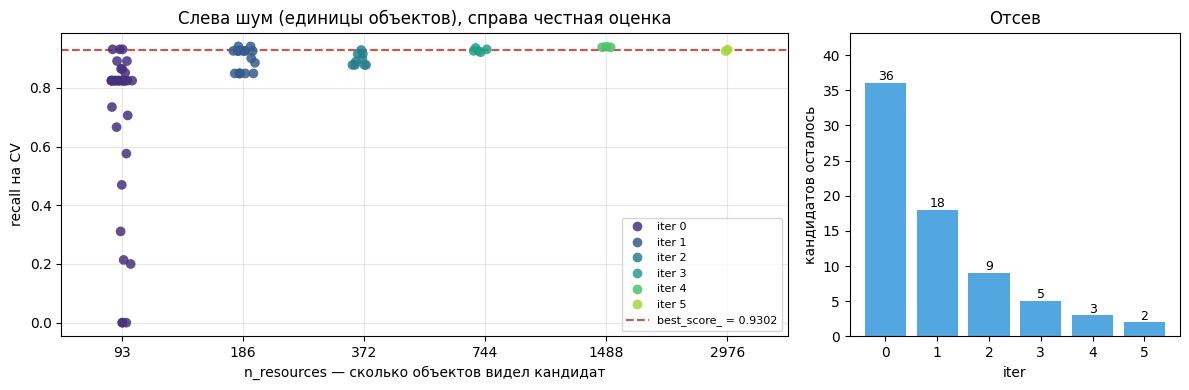

In [ ]:
res = pd.DataFrame(halving.cv_results_).copy()
res['iter_label'] = 'iter ' + res['iter'].astype(str)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4),
                               gridspec_kw={'width_ratios': [2.2, 1]})

# 1. Кандидаты по итерациям: ось X — сколько объектов видел кандидат,
#    ось Y — recall, цвет — номер итерации
sns.stripplot(data=res, x='n_resources', y='mean_test_score', hue='iter_label',
              dodge=False, size=7, alpha=0.85, palette='viridis', ax=ax1)
ax1.axhline(halving.best_score_, color='#e74c3c', linestyle='--',
            label=f'best_score_ = {halving.best_score_:.4f}')
ax1.set_xlabel('n_resources — сколько объектов видел кандидат')
ax1.set_ylabel('recall на CV')
ax1.set_title('Слева шум (единицы объектов), справа честная оценка')
ax1.legend(fontsize=8, loc='lower right')
ax1.grid(alpha=0.3)

# 2. Что график выше не показывает — сам отсев
counts = res.groupby('iter').size()
ax2.bar(counts.index.astype(str), counts.values, color='#3498db', alpha=0.85)
ax2.set_xlabel('iter')
ax2.set_ylabel('кандидатов осталось')
ax2.set_title('Отсев')
for i, v in enumerate(counts.values):
    ax2.text(i, v + 0.4, str(v), ha='center', fontsize=9)
ax2.set_ylim(0, counts.max() * 1.2)

plt.tight_layout()
plt.show()



*   График показывает, как менялась оценка (`mean_test_score`) различных комбинаций гиперпараметров по мере увеличения доступных им ресурсов (`n_resources`) на разных итерациях (`iter`).
*   Точки слева соответствуют ранним итерациям с малым количеством ресурсов. Точки справа - поздним итерациям с большим количеством ресурсов.
*   Цвет точек показывает номер итерации (например, темные - ранние, светлые - поздние).
*   Мы ожидаем увидеть, что:
    *   На ранних итерациях (слева) много точек с разным качеством.
    *   На последующих итерациях (правее, цвет светлее) точек становится меньше (худшие отсеялись), и они в среднем имеют более высокое качество.
    *   Оценка качества становится более стабильной (меньший разброс, меньший размер точек `std_test_score`, если используется) на поздних итерациях с большим количеством ресурсов.
*   Этот график помогает понять, насколько агрессивно происходил отсев и как менялись оценки "выживших" кандидатов.

#### Плюсы и минусы `HalvingSearch`

**Плюсы:**
*   **Скорость:** Потенциально **значительно** быстрее, чем `GridSearchCV` и `RandomizedSearchCV`, особенно если оценка модели на полном наборе данных дорогая.
*   **Эффективность использования ресурсов:** Не тратит много времени на плохие комбинации.

**Минусы:**
*   **Риск раннего отсева:** Хорошая комбинация ГП может показать себя не очень хорошо на малом количестве данных и быть отброшенной слишком рано.
*   **Чувствительность к `factor`:** Выбор `factor` влияет на компромисс между скоростью и риском отсева. Маленький `factor` (например, 2) — меньше риск, но медленнее. Большой `factor` (например, 5) — быстрее, но выше риск.
*   **Требование к модели:** Модель должна адекватно обучаться на подвыборках данных (`resource='n_samples'`). Для некоторых моделей или задач это может быть не так.
*   **Экспериментальный статус:** API может незначительно измениться в будущих версиях `scikit-learn`.

### 7. Когда использовать Halving Search?

*   **Основной кандидат:** Когда время обучения/оценки модели на полном датасете (даже с CV) заметное (минуты и больше).
*   **Хороший старт:** `HalvingRandomSearchCV` часто является отличной отправной точкой для ОГП, так как сочетает эффективность случайного поиска с экономией ресурсов Halving.
*   **Альтернатива Grid/Random:** Если `GridSearchCV` или `RandomizedSearchCV` работают слишком долго.

## Выводы

Мы рассмотрели три основных инструмента для автоматической оптимизации гиперпараметров в scikit-learn: GridSearchCV, RandomizedSearchCV и их более эффективные аналоги HalvingGridSearchCV и HalvingRandomSearchCV.

Давайте соберем ключевые характеристики в таблицу:



| Характеристика        | `GridSearchCV`                        | `RandomizedSearchCV`                     | `HalvingGridSearchCV` / `HalvingRandomSearchCV`                       |
| :-------------------- | :------------------------------------ | :--------------------------------------- | :-------------------------------------------------------------------- |
| **Принцип работы**    | Полный перебор по сетке               | Случайный выбор `n_iter` комбинаций      | Последовательный отсев худших на растущих ресурсах (данных)         |
| **Пространство**      | Дискретная сетка (`param_grid`)       | Списки или Распределения (`param_dist`) | Сетка (`param_grid`) или Распределения (`param_dist`)                 |
| **Гарантия оптимума** | Лучший **внутри сетки**              | Нет гарантии                             | Нет гарантии (лучший из *не отсеянных*)                             |
| **Эффективность**     | Низкая (экспоненц. сложность)       | Средняя/Высокая (зависит от `n_iter`)    | **Очень высокая** (если оценка модели дорогая)                      |
| **Ключевой параметр** | Размер сетки                          | `n_iter` (число итераций)                | `factor`, `min_resources` (управляют отсевом и ресурсами)          |
| **Основной плюс**     | Простота, исчерпывающий (в сетке)     | Эффективность, гибкость пространства     | **Скорость**                                                          |
| **Основной минус**    | **Медленный**                         | Случайность, нет гарантии                | Риск раннего отсева хороших ГП, чувствительность к `factor`           |
| **Когда использовать** | Мало ГП, небольшие сетки, простота | >2-3 ГП, непрерывные ГП, контроль времени | **Оценка модели дорогая**, хочется максимальной скорости, `Random` + `Halving` - хороший старт |


## Практические Советы


*   **Начните с `HalvingRandomSearchCV`:** Это часто лучший компромисс между скоростью, качеством поиска и гибкостью задания пространства. Задайте разумное `n_iter` (или `n_candidates`) и `factor` (обычно 2 или 3).
*   **Определите пространство поиска разумно:**
    *   Используйте лог-шкалу (`loguniform` или степени двойки/десятки) для параметров, меняющихся на порядки (регуляризация, learning rate).
    *   Не делайте диапазоны слишком узкими на старте, лучше потом сузить поиск вокруг найденной хорошей области.
    *   Не включайте слишком много гиперпараметров сразу, если не уверены в их важности.

*   **Используйте адекватную CV (`cv`):** `StratifiedKFold` для классификации (особенно несбалансированной), `KFold` для регрессии. Число фолдов (splits) влияет на время: меньше фолдов - быстрее, но оценка менее надежна (обычно 3-5-10).
*   **Фиксируйте `random_state`:** Для `RandomizedSearchCV`, `HalvingRandomSearchCV` и `StratifiedKFold(shuffle=True)` используйте `random_state` для воспроизводимости результатов.
*   **Анализируйте `cv_results_` и визуализируйте:** Не смотрите только на `best_params_`. Изучение таблицы `cv_results_` и построенных графиков (зависимость метрики от параметров, тепловые карты, процесс Halving) может дать понимание, какие параметры более важны, есть ли плато или резкие пики качества, как работает сам процесс поиска.

*   **Используйте Итеративный Подход к ОГП:** Оптимизация гиперпараметров — это часто не однократный запуск, а итеративный процесс исследования:
    1.  **Этап 1: Широкий Поиск.** Начните с `RandomizedSearchCV` или `HalvingRandomSearchCV` с *широкими диапазонами* и относительно *небольшим* количеством итераций (`n_iter` или бюджетом для Halving). Цель - быстро исследовать пространство и найти общие "перспективные" области значений для каждого гиперпараметра.
        *Пример:* `max_depth: randint(3, 30)`, `min_samples_leaf: randint(2, 50)`, `n_iter=50`.
    2.  **Этап 2: Суженный Поиск.** Проанализируйте результаты первого этапа (например, с помощью визуализаций из п. 4.1). Определите более узкие диапазоны вокруг лучших найденных значений. Запустите `GridSearchCV` (если параметров 1-2 и вы хотите точно исследовать сетку) или `RandomizedSearchCV`/`HalvingRandomSearchCV` с *большим* количеством итераций (`n_iter`) в этих *суженных диапазонах*. Цель - точно настроить параметры в найденной оптимальной области.
        *Пример (если первый этап показал оптимум около `max_depth=10`, `min_samples_leaf=8`):* `max_depth: [8, 9, 10, 11, 12]`, `min_samples_leaf: [5, 6, 7, 8, 9, 10]`, `n_iter=100` (для Random) или использовать GridSearch.
    *   **Преимущества:** Такой подход позволяет эффективно использовать вычислительные ресурсы: сначала быстро находим "где искать", а потом ищем "точно" в перспективном месте. Это часто дает лучшие результаты, чем один долгий запуск с огромной сеткой или очень большим `n_iter` в широком диапазоне.